# Microplate CIE Lab analysis

Version 2.2.0 | Google Colab | 12 columns × 8 rows

Run the hidden backend once, upload one photograph, detect the wells, then
adjust the correction form if necessary. Its preview shows the exact sampling
circles in black. Individual column shifts are arranged in four columns.
Finally run **Column results and CSV download**. The formatted CIELAB table
is displayed in the notebook and only one clean numeric CSV is downloaded:
`Column,L*,a*,b*,u_L,u_a,u_b`. No RGB statistics or RGB outputs are produced.

## Practical limits
Always inspect the overlay: 96 grid positions alone do not prove correct
well recognition. The detector assumes a mostly visible standard plate;
large rotations, occlusion, and strong perspective can require correction
or re-photography. Row numbers 1–8 refer to top-to-bottom image rows after
automatic rotation, not independently verified manufacturer labels.
`is_empty` is only a low-saturation heuristic, not proof of physical emptiness.
The CSV download may require browser permission.


In [ ]:
#@title Computational backend · run once { display-mode: "form" }
import sys, subprocess, importlib.util
required = ['numpy', 'pandas', 'matplotlib', 'opencv-python', 'scikit-image', 'scipy', 'ipython', 'jinja2', 'ipywidgets']
spec_names = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'opencv-python': 'cv2',
    'scikit-image': 'skimage',
    'scipy': 'scipy',
    'ipython': 'IPython',
    'jinja2': 'jinja2',
    'ipywidgets': 'ipywidgets',
}
missing = [pkg for pkg in required if importlib.util.find_spec(spec_names[pkg]) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + missing)

from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from skimage import color
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    files = None
    IN_COLAB = False
from IPython.display import display, Markdown
import importlib.metadata
import hashlib
import ipywidgets as widgets

plt.rcParams['figure.dpi'] = 140
plt.rcParams['axes.grid'] = True
OUTPUT_DIR = Path('output')
OUTPUT_DIR.mkdir(exist_ok=True)


"""Improved well detection for 96-well microplate images.

Pipeline
--------
1. Rotate so the plate's long side is horizontal (12 columns across).
2. Collect well candidates from three complementary detectors:
   - multi-scale annulus (ring) correlation on the gradient-magnitude image,
     which responds to well rims regardless of the liquid color;
   - Hough circles (as in the original notebook);
   - ellipse-fitted contours from adaptive thresholding (both polarities).
3. Merge near-duplicate candidates (within 0.35 pitch).
4. Fit a 2D affine grid  p(r,c) = p0 + c*u + r*v  by alternating
   gated unique candidate-to-node assignment and robust least squares.
   This handles moderate perspective, rotation and non-square pitch,
   tolerates missing detections (e.g. whole columns of clear wells)
   and rejects outliers (e.g. circles on the plate rim).
5. Refine each grid node locally using the ring-correlation response,
   bounded to a fraction of the pitch; wells without support keep the
   grid prediction and are marked as inferred.
6. Report coverage diagnostics (how many of the 96 nodes are supported).
"""

from scipy.spatial import cKDTree

N_COLS, N_ROWS = 12, 8
INNER_RADIUS_FRAC = 0.5
OUTLIER_Z = 2.5
LOCAL_SEARCH_FRAC = 0.05
LOCAL_STEP = 1
DARKER_WELL_BIAS = 6.0
EMPTY_WELL_SAT_THRESHOLD = 12.0

# Tunables of the improved detector
RING_SCALES = (0.9, 1.0, 1.1)      # annulus scale relative to the pitch
RING_R_OUT_FRAC = 0.56             # annulus outer radius / pitch (covers the well rim)
RING_R_IN_FRAC = 0.40              # annulus inner radius / pitch
DISC_R_FRAC = 0.30                  # interior-evidence disc radius / pitch
DISC_WEIGHT = 1.0                   # weight of the disc channel in the evidence
RING_RESPONSE_MIN = 0.25            # global peak threshold
RING_REFINE_MIN = 0.12              # lower threshold for per-node refinement
MERGE_FRAC = 0.35                   # duplicate merge distance in pitch units
ASSIGN_GATE = 0.5                   # assignment gate in pitch units
REFINE_MAX_MOVE = 0.15              # per-node refinement bound in pitch units
R_LATTICE_FRAC = 0.42               # sampling circle radius / pitch


# ----------------------------------------------------------------------------
# Basic helpers
# ----------------------------------------------------------------------------


def rotate_long_side_horizontal(img_bgr):
    """Rotate portrait images so that the 12-column direction is horizontal."""
    if img_bgr.shape[0] > img_bgr.shape[1]:
        return cv2.rotate(img_bgr, cv2.ROTATE_90_CLOCKWISE)
    return img_bgr


def estimate_grid_extent(img_shape):
    """First-guess well diameter from the image size (plate fills the frame)."""
    h, w = img_shape[:2]
    est_diam_x = w / 14.0
    est_diam_y = h / 10.0
    return float(np.median([est_diam_x, est_diam_y]))


# ----------------------------------------------------------------------------
# Detector 1: multi-scale ring (annulus) correlation on gradient magnitude
# ----------------------------------------------------------------------------

def gradient_magnitude(gray_f32):
    gx = cv2.Sobel(gray_f32, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray_f32, cv2.CV_32F, 0, 1, ksize=3)
    gmag = cv2.magnitude(gx, gy)
    return cv2.GaussianBlur(gmag, (0, 0), 2)


def ring_response_maps(img_bgr, pitch):
    """Well-position evidence: annulus correlation on the gradient magnitude
    plus an interior "disc" channel.

    The annulus channel responds to the well rim; the disc channel responds
    to the well interior differing from the surrounding plastic (either
    polarity).  The disc channel is robust to edge softening (e.g. rotated
    or blurred photos) where rim evidence alone becomes ambiguous between
    well centres and midpoints between wells.

    Template radii are pitch-relative.  Returns (maps, radii): per scale,
    the combined evidence map where map[y, x] is the evidence for a well
    centered at (x, y), and the template mid-radius.
    """
    h, w = img_bgr.shape[:2]
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
    gmag = gradient_magnitude(gray)

    # interior disc channel (single scale), suppressed along straight edges
    # where gradients are anisotropic (wells are isotropic structures)
    disc_map = _well_interior_map(img_bgr, pitch)

    maps, radii = [], []
    for scale in RING_SCALES:
        r_out = RING_R_OUT_FRAC * pitch * scale
        r_in = RING_R_IN_FRAC * pitch * scale
        sz = int(2 * r_out + 3)
        if sz > min(h, w):
            continue
        yy, xx = np.mgrid[0:sz, 0:sz] - sz // 2
        d = np.sqrt(xx ** 2 + yy ** 2)
        tmpl = ((d >= r_in) & (d <= r_out)).astype(np.float32)
        res = cv2.matchTemplate(gmag, tmpl, cv2.TM_CCOEFF_NORMED)
        # embed into full-size map so map[y, x] = response at center (x, y)
        full = np.full((h, w), -1.0, dtype=np.float32)
        off = sz // 2
        full[off:off + res.shape[0], off:off + res.shape[1]] = res
        maps.append(full + DISC_WEIGHT * disc_map)
        radii.append(0.5 * (r_in + r_out))
    return maps, radii, disc_map


def gradient_coherence(img_bgr, pitch):
    """Structure-tensor coherence: ~1 along straight edges, ~0 at wells.

    Well neighbourhoods contain radially arranged edges (isotropic
    gradients); straight edges (photo borders, plate rim, light-box
    edges) have unidirectional gradients.
    """
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    sigma = 0.25 * pitch
    sxx = cv2.GaussianBlur(gx * gx, (0, 0), sigma)
    syy = cv2.GaussianBlur(gy * gy, (0, 0), sigma)
    sxy = cv2.GaussianBlur(gx * gy, (0, 0), sigma)
    tr = sxx + syy + 1e-6
    disc2 = np.sqrt(np.maximum((sxx - syy) ** 2 + 4 * sxy ** 2, 0.0))
    return np.clip(disc2 / tr, 0.0, 1.0)


def _well_interior_map(img_bgr, pitch):
    """Well-interior evidence: disc-template correlation, edge- and
    flat-region-suppressed.

    A filled-disc template correlates strongly with the liquid disc
    inside a well and poorly with the plastic between wells, which
    disambiguates well centres from midpoints between wells.  Two
    gates suppress spurious responses:
    - straight edges (plate rim, photo borders): gradient-coherence
      gate (wells are isotropic, edges are anisotropic);
    - flat regions (background, plastic): local-standard-deviation
      gate (normalised correlation is noise-driven where variance ~ 0).
    """
    h, w = img_bgr.shape[:2]
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
    r_disc = DISC_R_FRAC * pitch
    sz_d = int(2 * r_disc + 3)
    if sz_d > min(h, w):
        return np.zeros((h, w), dtype=np.float32)
    yy, xx = np.mgrid[0:sz_d, 0:sz_d] - sz_d // 2
    disc = (np.sqrt(xx ** 2 + yy ** 2) <= r_disc).astype(np.float32)
    gray_s = cv2.GaussianBlur(gray, (0, 0), 2)
    res_d = cv2.matchTemplate(gray_s, disc, cv2.TM_CCOEFF_NORMED)
    disc_map = np.zeros((h, w), dtype=np.float32)
    off_d = sz_d // 2
    disc_map[off_d:off_d + res_d.shape[0], off_d:off_d + res_d.shape[1]] = np.abs(res_d)
    # flat-region gate: local std over a disc-sized window
    k_d = max(3, int(round(2 * r_disc)) | 1)
    m1 = cv2.boxFilter(gray, cv2.CV_32F, (k_d, k_d), normalize=True)
    m2 = cv2.boxFilter(gray * gray, cv2.CV_32F, (k_d, k_d), normalize=True)
    local_std = np.sqrt(np.maximum(m2 - m1 * m1, 0.0))
    std_gate = np.clip(local_std / (0.03 * 255.0), 0.0, 1.0)
    # straight-edge gate
    coh = gradient_coherence(img_bgr, pitch)
    return (disc_map * std_gate * (1.0 - coh)).astype(np.float32)


def ring_candidates(maps, radii, pitch):
    """Local maxima of the (max over scales) ring response."""
    best = np.max(maps, axis=0)
    best_scale_idx = np.argmax(maps, axis=0)
    nms_k = max(3, int(round(0.75 * pitch)))
    mx = cv2.dilate(best, np.ones((nms_k, nms_k), np.uint8))
    peaks = (best == mx) & (best > RING_RESPONSE_MIN)
    ys, xs = np.nonzero(peaks)
    if len(xs) == 0:
        return pd.DataFrame(columns=['x', 'y', 'r', 'quality'])
    rs = np.array(radii)[best_scale_idx[ys, xs]]
    return pd.DataFrame({
        'x': xs.astype(float), 'y': ys.astype(float),
        'r': rs, 'quality': best[ys, xs]
    })


# ----------------------------------------------------------------------------
# Detector 2: Hough circles (kept from the original notebook)
# ----------------------------------------------------------------------------

def circle_masks(shape, x, y, r):
    h, w = shape[:2]
    Y, X = np.ogrid[:h, :w]
    d2 = (X - x) ** 2 + (Y - y) ** 2
    r_in = max(4, int(round(0.55 * r)))
    r_mid1 = max(r_in + 2, int(round(0.75 * r)))
    r_mid2 = max(r_mid1 + 2, int(round(1.05 * r)))
    r_out1 = max(r_mid2 + 2, int(round(1.10 * r)))
    r_out2 = max(r_out1 + 2, int(round(1.45 * r)))
    inner = d2 <= r_in ** 2
    midring = (d2 >= r_mid1 ** 2) & (d2 <= r_mid2 ** 2)
    outer = (d2 >= r_out1 ** 2) & (d2 <= r_out2 ** 2)
    return inner, midring, outer


def circle_contrast_score(gray, x, y, r):
    inner, midring, outer = circle_masks(gray.shape, x, y, r)
    if inner.sum() < 10 or midring.sum() < 10 or outer.sum() < 10:
        return -np.inf
    mu_in = gray[inner].mean()
    mu_mid = gray[midring].mean()
    mu_out = gray[outer].mean()
    return float((mu_mid - mu_in) + 0.35 * (mu_out - mu_in))


def hough_candidates(img_bgr, est_diam):
    h, w = img_bgr.shape[:2]
    est_r = est_diam / 2.0
    gray_crop = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    gray_crop = cv2.medianBlur(gray_crop, 5)

    all_candidates = []
    for param2 in range(18, 36, 2):
        circles = cv2.HoughCircles(
            gray_crop, cv2.HOUGH_GRADIENT, dp=1.2,
            minDist=int(round(0.75 * est_diam)),
            param1=100, param2=param2,
            minRadius=max(10, int(round(0.65 * est_r))),
            maxRadius=int(round(1.35 * est_r))
        )
        if circles is None:
            continue
        raw = np.round(circles[0]).astype(int)
        df = pd.DataFrame(raw, columns=['x', 'y', 'r'])
        all_candidates.append(df)
    if not all_candidates:
        return pd.DataFrame(columns=['x', 'y', 'r', 'quality'])
    raw = pd.concat(all_candidates, ignore_index=True).drop_duplicates(subset=['x', 'y', 'r'])
    gray_full = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    scores = [circle_contrast_score(gray_full, int(x), int(y), int(r))
              for x, y, r in raw[['x', 'y', 'r']].to_numpy()]
    raw['quality'] = np.clip(np.asarray(scores, dtype=float), 0, None)
    return raw.reset_index(drop=True)


# ----------------------------------------------------------------------------
# Detector 3: contours from adaptive thresholding
# ----------------------------------------------------------------------------

def contour_candidates(img_bgr, est_diam):
    h, w = img_bgr.shape[:2]
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    gray = cv2.medianBlur(gray, 5)
    r_lo, r_hi = 0.4 * est_diam / 2, 1.6 * est_diam / 2
    a_lo, a_hi = np.pi * r_lo ** 2, np.pi * r_hi ** 2
    rows = []
    for th in (
        cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY_INV, 21, 5),
        cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 21, 5),
    ):
        cnts, _ = cv2.findContours(th, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
        for c in cnts:
            a = cv2.contourArea(c)
            if a < a_lo or a > a_hi or len(c) < 8:
                continue
            (cx, cy), (MA, ma), _ = cv2.fitEllipse(c)
            ecc = ma / max(MA, 1e-6)
            circ = 4 * np.pi * a / max(cv2.arcLength(c, True), 1e-6)
            if not (0.55 < ecc < 1.8 and circ > 0.55):
                continue
            rows.append({'x': float(cx), 'y': float(cy),
                         'r': float((MA + ma) / 4), 'quality': float(circ)})
    if not rows:
        return pd.DataFrame(columns=['x', 'y', 'r', 'quality'])
    return pd.DataFrame(rows).drop_duplicates(subset=['x', 'y', 'r']).reset_index(drop=True)


# ----------------------------------------------------------------------------
# Merge candidates
# ----------------------------------------------------------------------------

def merge_candidates(cand_list, pitch):
    """Spatially merge candidates closer than MERGE_FRAC * pitch.

    Quality-weighted mean position; radius from the highest-quality member.
    """
    cand_list = [c for c in cand_list if len(c) > 0]
    if not cand_list:
        raise RuntimeError('No well candidates found by any detector.')
    # normalise each detector's quality to [0.1, 1] so scales are comparable
    norm_list = []
    for c in cand_list:
        c = c.copy()
        q = c['quality'].to_numpy(dtype=float)
        q = np.where(np.isfinite(q), q, 0.0)
        qmin, qmax = float(np.min(q)), float(np.max(q))
        if qmax > qmin:
            c['quality'] = 0.1 + 0.9 * (q - qmin) / (qmax - qmin)
        else:
            c['quality'] = 0.5
        norm_list.append(c)
    allc = pd.concat(norm_list, ignore_index=True)
    pts = allc[['x', 'y']].to_numpy(dtype=float)
    q = allc['quality'].to_numpy(dtype=float)
    q = np.where(np.isfinite(q) & (q >= 0), q, 0.0) + 1e-6
    r = allc['r'].to_numpy(dtype=float)

    tree = cKDTree(pts)
    pairs = tree.query_pairs(MERGE_FRAC * pitch)
    parent = np.arange(len(pts))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, j in pairs:
        ri, rj = find(i), find(j)
        if ri != rj:
            parent[ri] = rj
    groups = {}
    for i in range(len(pts)):
        groups.setdefault(find(i), []).append(i)

    rows = []
    for members in groups.values():
        wq = q[members]
        x = float(np.sum(wq * pts[members, 0]) / np.sum(wq))
        y = float(np.sum(wq * pts[members, 1]) / np.sum(wq))
        best = members[int(np.argmax(wq))]
        rows.append({'x': x, 'y': y, 'r': float(r[best]),
                     'quality': float(wq.max()), 'n_sources': len(members)})
    return pd.DataFrame(rows).sort_values('quality', ascending=False).reset_index(drop=True)


# ----------------------------------------------------------------------------
# Robust affine grid fit
# ----------------------------------------------------------------------------


def _kde_lines(coords, weights, pitch, n_lines):
    """Locate grid-line positions as weighted KDE peaks (robust to outliers).

    Returns (line_positions, j_of, A, B, j0):
      - line_positions: sorted coordinates of the detected grid lines
      - j_of: lattice index of each line relative to the first line
      - A, B: robust line fit  position ~ A + B * j
      - j0: window start index so the grid has exactly n_lines slots
    """
    coords = np.asarray(coords, dtype=float)
    weights = np.asarray(weights, dtype=float)
    bw = 0.12 * pitch
    grid = np.linspace(coords.min() - pitch, coords.max() + pitch, 2400)
    diff = grid[:, None] - coords[None, :]
    dens = (weights[None, :] * np.exp(-0.5 * (diff / bw) ** 2)).sum(axis=1)

    # local maxima, strongest first, minimum separation 0.6 * pitch
    peaks = []
    for i in range(1, len(grid) - 1):
        if dens[i] > dens[i - 1] and dens[i] >= dens[i + 1]:
            peaks.append((dens[i], grid[i]))
    peaks.sort(reverse=True)
    kept = []
    for d, x in peaks:
        if all(abs(x - xk) >= 0.6 * pitch for _, xk in kept):
            kept.append((d, x))
        if len(kept) >= n_lines + 2:
            break
    kept.sort(key=lambda t: t[1])
    pos = np.array([x for _, x in kept])
    weights_k = np.array([d for d, _ in kept])
    if len(pos) < 2:
        return pos, np.zeros(len(pos), dtype=int), float(pos[0]) if len(pos) else 0.0, pitch, 0

    # ---- fit an arithmetic progression to the peak positions ----
    # Small exhaustive search over (offset A, spacing B); robust to missing
    # lines and spurious peaks.  A lattice is only valid if its matched
    # lines fit into n_lines slots.  Score: matched line count, then matched
    # quality mass, then closeness of B to the pitch prior.
    best = None
    for B in np.linspace(0.82, 1.18, 37) * pitch:
        for A in np.linspace(0.0, B, 40, endpoint=False):
            k = np.round((pos - A) / B)
            resid = np.abs(pos - (A + B * k))
            m = resid < 0.15 * pitch
            if not m.any():
                continue
            ku = np.unique(k[m])
            if ku.max() - ku.min() > n_lines - 1:
                continue  # grid would need more than n_lines slots
            sc = (len(ku), float(weights_k[m].sum()), -abs(B / pitch - 1.0))
            if best is None or sc > best[0]:
                best = (sc, float(A), float(B))
    if best is None:
        return pos, np.arange(len(pos)), float(pos[0]), pitch, 0
    _, A, B = best

    # per-line position = weighted median of the candidates assigned to the
    # line (more accurate than the KDE peak position)
    k_c = np.round((coords - A) / B)
    d_c = np.abs(coords - (A + B * k_c))
    line_pos = {}
    for j in np.unique(k_c[d_c < 0.18 * pitch]):
        sel = (k_c == j) & (d_c < 0.18 * pitch)
        wj = weights[sel]
        cj = coords[sel]
        order = np.argsort(cj)
        cw = np.cumsum(wj[order])
        line_pos[int(j)] = float(cj[order][np.searchsorted(cw, 0.5 * cw[-1])])
    if len(line_pos) < 2:
        line_pos = {int(j): float(p) for j, p in zip(np.round((pos - A) / B), pos)}

    # robust refinement: iteratively drop off-lattice lines (e.g. the plate
    # rim, which sits close to but not exactly on the well lattice)
    while len(line_pos) >= 3:
        js = np.array(sorted(line_pos), dtype=float)
        vals = np.array([line_pos[int(j)] for j in js])
        B2, A2 = np.polyfit(js, vals, 1)
        resid = np.abs(vals - (A2 + B2 * js))
        if resid.max() <= 0.10 * abs(B2):
            break
        worst = int(js[int(np.argmax(resid))])
        del line_pos[worst]

    js = np.array(sorted(line_pos))
    vals = np.array([line_pos[int(j)] for j in js], dtype=float)
    if len(js) >= 2:
        B2, A2 = np.polyfit(js.astype(float), vals, 1)
    else:
        A2, B2 = float(vals[0]) if len(vals) else 0.0, pitch
    j_of = js.astype(int)

    # window start: exactly n_lines slots containing all observed lines
    jmin, jmax = int(j_of.min()), int(j_of.max())
    span = jmax - jmin
    # per-line candidate mass (quality sum within a quarter pitch of the line)
    line_mass = {}
    for j in j_of:
        sel = np.abs(coords - (A2 + B2 * j)) < 0.25 * abs(B2)
        line_mass[int(j)] = float(weights[sel].sum())

    if span > n_lines - 1:
        # spurious lines (e.g. the plate rim) are present: choose the
        # n_lines-slot window with the greatest total line mass
        extra = span - (n_lines - 1)
        j0, best_m = jmin, -1.0
        for k in range(extra + 1):
            ja = jmin + k
            m = sum(line_mass.get(ja + t, 0.0) for t in range(n_lines))
            if m > best_m:
                best_m, j0 = m, ja
    elif span < n_lines - 1:
        missing = (n_lines - 1) - span
        opt_left = jmin - missing   # missing slots added on the left
        opt_right = jmin           # missing slots added on the right
        lo_c, hi_c = coords.min(), coords.max()

        def fits(ja):
            lo = A2 + B2 * ja
            hi = A2 + B2 * (ja + n_lines - 1)
            return (lo >= lo_c - 0.7 * pitch) and (hi <= hi_c + 0.7 * pitch)

        if fits(opt_right):
            j0 = opt_right
        elif fits(opt_left):
            j0 = opt_left
        else:
            j0 = opt_right
    else:
        j0 = jmin
    return pos, j_of, float(A2), float(B2), int(j0)


def _pca_axes(pts):
    """Principal axes of the candidate cloud (long axis -> columns).

    Makes the initialisation rotation-invariant: the 12-column direction is
    the cloud's long axis.  Axes are oriented right (x>0) and down (y>0).
    """
    mean = pts.mean(axis=0)
    d = pts - mean
    cov = (d.T @ d) / max(len(pts), 1)
    evals, evecs = np.linalg.eigh(cov)  # ascending eigenvalues
    ax_long = evecs[:, np.argmax(evals)]
    ax_short = evecs[:, np.argmin(evals)]
    if ax_long[0] < 0:
        ax_long = -ax_long
    if ax_short[1] < 0:
        ax_short = -ax_short
    return mean, ax_long, ax_short


def _solve_affine(col_idx, row_idx, pts, weights=None):
    """(Weighted) least squares p = p0 + c*u + r*v (per coordinate)."""
    A = np.column_stack([np.ones(len(col_idx)), col_idx, row_idx]).astype(float)
    if weights is not None:
        sw = np.sqrt(np.clip(np.asarray(weights, dtype=float), 0.05, 1.0))
        A = A * sw[:, None]
        pts = pts * sw[:, None]
    bx, *_ = np.linalg.lstsq(A, pts[:, 0], rcond=None)
    by, *_ = np.linalg.lstsq(A, pts[:, 1], rcond=None)
    return np.array([bx[0], by[0]]), np.array([bx[1], by[1]]), np.array([bx[2], by[2]])


def _node_evidence(evidence, p0, u, v, n_cols, n_rows):
    """Discreteness-scored well evidence at the grid node positions.

    Wells are discrete: evidence is high at the nodes and low at the
    half-pitch midpoints between them.  A straight line (plate rim, photo
    border) that masquerades as a grid row/column is continuous, so its
    midpoint evidence is as high as at the nodes and the score collapses.
    Returns mean(node evidence - midpoint evidence); out-of-bounds
    positions count as 0.
    """
    h, w = evidence.shape[:2]
    u_hat = u / (np.linalg.norm(u) + 1e-9)
    v_hat = v / (np.linalg.norm(v) + 1e-9)

    def sample(p):
        x, y = int(round(p[0])), int(round(p[1]))
        if 0 <= x < w and 0 <= y < h:
            return float(evidence[y, x])
        return 0.0

    vals = []
    for r_i in range(n_rows):
        for c_i in range(n_cols):
            p = p0 + c_i * u + r_i * v
            node_ev = sample(p)
            mids = [p - 0.5 * u_hat * np.linalg.norm(u),
                    p + 0.5 * u_hat * np.linalg.norm(u),
                    p - 0.5 * v_hat * np.linalg.norm(v),
                    p + 0.5 * v_hat * np.linalg.norm(v)]
            mid_ev = np.mean([sample(m) for m in mids])
            vals.append(node_ev - mid_ev)
    return float(np.mean(vals)) if vals else 0.0


def _outer_wells_check(evidence, p0, u, v, pts, ax_c, ax_r, pitch,
                       n_cols=N_COLS, n_rows=N_ROWS,
                       rel_thresh=0.6, min_gap=0.35, max_gap=2.4):
    """Reject a grid window whose nearest outer candidate line is real wells.

    For each side of the fitted grid, look at candidates just outside the
    grid edge.  The nearest such line is normally the plate rim or the
    photo border, where well evidence is low.  If instead it carries
    well-like evidence at the grid's line positions, the window has
    excluded a genuine row/column of wells and is wrong.  Sides with no
    nearby outer candidates (plate cut off at the photo edge) are ignored.
    """
    if evidence is None or len(pts) == 0:
        return True
    h, w = evidence.shape[:2]

    def sample(p):
        x, y = int(round(p[0])), int(round(p[1]))
        if 0 <= x < w and 0 <= y < h:
            return float(evidence[y, x])
        return None

    node_vals = []
    for r_i in range(n_rows):
        for c_i in range(n_cols):
            s = sample(p0 + c_i * u + r_i * v)
            if s is not None:
                node_vals.append(s)
    if not node_vals:
        return True
    node_mean = float(np.mean(node_vals))
    if node_mean <= 0:
        return True

    sides = [
        ([p0 + r * v for r in range(n_rows)], -1.0, ax_c),
        ([p0 + (n_cols - 1) * u + r * v for r in range(n_rows)], 1.0, ax_c),
        ([p0 + c * u for c in range(n_cols)], -1.0, ax_r),
        ([p0 + c * u + (n_rows - 1) * v for c in range(n_cols)], 1.0, ax_r),
    ]
    for base, sgn, axis in sides:
        q_edge = float(np.median([b @ axis for b in base]))
        q_all = pts @ axis
        d = sgn * (q_all - q_edge)
        outer_d = np.sort(d[(d > min_gap * pitch) & (d < max_gap * pitch)])
        if len(outer_d) == 0:
            continue
        # cluster outer candidates into lines (1D, pitch-relative tolerance)
        clusters = []
        cur = [outer_d[0]]
        for x in outer_d[1:]:
            if x - cur[-1] <= 0.25 * pitch:
                cur.append(x)
            else:
                clusters.append(float(np.median(cur)))
                cur = [x]
        clusters.append(float(np.median(cur)))
        # in the rim band (0.8-1.7 pitches out) any line carrying
        # well-like evidence means a real well line was excluded
        for d_line in clusters:
            if not (0.8 * pitch <= d_line <= 1.7 * pitch):
                continue
            vals = []
            for b in base:
                s = sample(b + sgn * d_line * axis)
                if s is not None:
                    vals.append(s)
            if len(vals) < 0.4 * len(base):
                continue
            if float(np.mean(vals)) > rel_thresh * node_mean:
                return False
    return True


def fit_affine_grid(cands, pitch, n_cols=N_COLS, n_rows=N_ROWS, n_iter=30, init_cands=None, ax_override=None, evidence=None):
    """Alternating gated assignment and affine refit. Returns (lattice, info).

    init_cands (optional, e.g. the ring-correlation candidates) is used for
    the initialisation only; the alternating fit itself uses all candidates.

    lattice: DataFrame with row/column indices 1..8 / 1..12 and node centres.
    info: dict with fit diagnostics.
    """
    pts_all = cands[['x', 'y']].to_numpy(dtype=float)
    cand_quality = np.clip(
        cands['quality'].to_numpy(dtype=float) if 'quality' in cands else 1.0,
        0.05, 1.0)

    # ---- initialisation in a PCA-derotated frame (rotation-invariant) ----
    pts_init = init_cands[['x', 'y']].to_numpy(dtype=float) if init_cands is not None else pts_all
    q_init = np.clip(
        init_cands['quality'].to_numpy(dtype=float) if init_cands is not None else cand_quality,
        0.05, 1.0)
    if ax_override is not None:
        ax_c = np.asarray(ax_override[0], dtype=float)
        ax_r = np.asarray(ax_override[1], dtype=float)
        mean = pts_init.mean(axis=0)
    else:
        mean, ax_c, ax_r = _pca_axes(pts_init)
    qx = (pts_init - mean) @ ax_c  # position along the column direction
    qy = (pts_init - mean) @ ax_r  # position along the row direction

    # grid lines from weighted KDE peaks (robust to spurious candidates).
    # Columns are fitted first; candidates lying near a column line are then
    # up-weighted for the row fit, and vice versa for a second column pass.
    # Long straight edges (plate rim, photo borders) produce strings of
    # candidates that are NOT concentrated at grid positions, so this
    # 2D-consistency filter suppresses them.
    qx_init, qy_init = qx, qy  # init candidates (ring) in the PCA frame

    _, _, Ac, Bc, c0 = _kde_lines(qx, q_init, pitch, n_cols)
    col_lines = Ac + Bc * np.arange(c0, c0 + n_cols)

    def _prox_weights(q_all, lines, tol):
        d = np.min(np.abs(q_all[:, None] - lines[None, :]), axis=1)
        return np.where(d < tol, 1.0, 0.15)

    w_col_init = _prox_weights(qx_init, col_lines, 0.3 * abs(Bc))
    _, _, Ar, Br, r0 = _kde_lines(qy, q_init * w_col_init, pitch, n_rows)
    row_lines = Ar + Br * np.arange(r0, r0 + n_rows)

    w_row_init = _prox_weights(qy_init, row_lines, 0.3 * abs(Br))
    _, _, Ac, Bc, c0 = _kde_lines(qx, q_init * w_row_init, pitch, n_cols)
    col_lines = Ac + Bc * np.arange(c0, c0 + n_cols)

    # combined 2D-consistency weights for all (merged) candidates
    qx_all = (pts_all - mean) @ ax_c
    qy_all = (pts_all - mean) @ ax_r
    w_2d = (_prox_weights(qx_all, col_lines, 0.3 * abs(Bc))
            * _prox_weights(qy_all, row_lines, 0.3 * abs(Br)))

    # the same 2D-consistency weights apply inside the alternating fit and
    # to the fit-quality score, so rim/border strings cannot outvote wells
    cand_quality = cand_quality * w_2d

    # ---- alternating fit, retried over neighbouring windows ----
    # The initial window (which 12 of the detected lines are the columns,
    # which 8 are the rows) can be off by one when rim lines are nearly
    # on-lattice or edge wells are undetected; retrying the fit over the
    # neighbouring windows and keeping the best result makes the fit
    # robust to that.
    def _alternate(p0, u, v):
        for it in range(n_iter):
            cols = np.arange(n_cols)
            rows = np.arange(n_rows)
            nodes = (p0[None, None] + cols[None, :, None] * u[None, None]
                      + rows[:, None, None] * v[None, None])  # (rows, cols, 2)
            flat_nodes = nodes.reshape(-1, 2)

            tree = cKDTree(flat_nodes)
            d, idx = tree.query(pts_all)
            gate = 0.45 * pitch if it < 3 else ASSIGN_GATE * pitch
            ok = d < gate
            order = np.argsort(d)
            node_taken = {}
            assign_node = -np.ones(len(pts_all), dtype=int)
            for cand_i in order:
                if not ok[cand_i]:
                    continue
                n = idx[cand_i]
                if n in node_taken:
                    continue
                node_taken[n] = cand_i
                assign_node[cand_i] = n
            assigned_mask = assign_node >= 0

            if assigned_mask.sum() < 6:
                raise RuntimeError('Affine grid fit failed: too few assigned candidates.')

            res_cur = np.linalg.norm(pts_all[assigned_mask] - flat_nodes[assign_node[assigned_mask]], axis=1)

            a_idx = np.nonzero(assigned_mask)[0]
            keep = res_cur < max(0.25 * pitch, 2.5 * np.median(res_cur))
            if keep.sum() < 6:
                keep = np.ones(len(a_idx), dtype=bool)
            a_idx = a_idx[keep]
            cols_a = assign_node[a_idx] % n_cols
            rows_a = assign_node[a_idx] // n_cols
            w_a = cand_quality[a_idx]
            p0_new, u_new, v_new = _solve_affine(cols_a, rows_a, pts_all[a_idx], weights=w_a)

            # early iterations: keep the grid axis-aligned in the PCA frame.
            # The true grid is axis-aligned there to within a fraction of a
            # degree, so this prevents the fit from cascading into a sheared
            # (diagonal) local optimum when the initial assignment mixes
            # neighbouring rows.
            if it < 4:
                u_new = ax_c * float(u_new @ ax_c)
                v_new = ax_r * float(v_new @ ax_r)

            if u_new[0] < 0:
                u_new = -u_new
                p0_new = p0_new + (n_cols - 1) * u_new
            if v_new[1] < 0:
                v_new = -v_new
                p0_new = p0_new + (n_rows - 1) * v_new

            moved = (np.linalg.norm(p0_new - p0) + np.linalg.norm(u_new - u)
                     + np.linalg.norm(v_new - v))
            p0, u, v = p0_new, u_new, v_new
            if moved < 1e-6 and it >= 3:
                break
        return p0, u, v, assign_node, flat_nodes

    best_result = None
    best_rejected = None
    for dc in (0, 1, -1):
        for dr in (0, 1, -1):
            q00 = np.array([Ac + Bc * (c0 + dc), Ar + Br * (r0 + dr)])
            u_i = ax_c * Bc
            v_i = ax_r * Br
            p0_i = mean + ax_c * q00[0] + ax_r * q00[1]
            try:
                p0_f, u_f, v_f, assign_node, flat_nodes = _alternate(p0_i, u_i, v_i)
            except RuntimeError:
                continue
            n_ass = float(cand_quality[assign_node >= 0].sum())
            res = np.linalg.norm(pts_all[assign_node >= 0] - flat_nodes[assign_node[assign_node >= 0]], axis=1)
            # primary criterion: mean well evidence at the 96 node positions.
            # A window that includes a rim/border line and drops an edge row
            # of real wells loses here, because rims carry little evidence
            # under the node positions while wells carry a lot.
            if evidence is not None:
                ev_nodes = _node_evidence(evidence, p0_f, u_f, v_f, n_cols, n_rows)
            else:
                ev_nodes = 0.0
            score = (ev_nodes, n_ass, -float(np.median(res)))
            entry = (score, p0_f, u_f, v_f, assign_node, flat_nodes, res)
            outer_ok = _outer_wells_check(evidence, p0_f, u_f, v_f, pts_all,
                                         ax_c, ax_r, pitch, n_cols, n_rows)
            if outer_ok:
                if best_result is None or score > best_result[0]:
                    best_result = entry
            else:
                if best_rejected is None or score > best_rejected[0]:
                    best_rejected = entry
    if best_result is None:
        best_result = best_rejected
    if best_result is None:
        raise RuntimeError('Affine grid fit failed for all window candidates.')
    (_, p0, u, v, assign_node, flat_nodes, res) = best_result

    # final lattice
    lattice_rows = []
    for r_i in range(n_rows):
        for c_i in range(n_cols):
            centre = p0 + c_i * u + r_i * v
            lattice_rows.append({
                'row': r_i + 1, 'column': c_i + 1,
                'x_lattice': float(centre[0]), 'y_lattice': float(centre[1])
            })
    lattice = pd.DataFrame(lattice_rows)
    lattice['r_lattice'] = np.nan

    info = {
        'pitch_px': pitch,
        'n_assigned': int((assign_node >= 0).sum()),
        'assign_node': assign_node,
        'residual_px_median': float(np.median(res)) if len(res) else np.nan,
        'residual_px_max': float(res.max()) if len(res) else np.nan,
        'p0': p0, 'u': u, 'v': v
    }
    return lattice, info


# ----------------------------------------------------------------------------
# Per-node refinement and support marking
# ----------------------------------------------------------------------------

def refine_lattice(lattice, cands, ring_maps, radii, pitch, r_fallback):
    """Local refinement of every node.

    For nodes with candidates inside the assignment gate the best candidate
    is chosen by ring-response quality with a distance penalty, and the
    node movement is bounded by REFINE_MAX_MOVE * pitch.  Nodes without a
    candidate are moved to the strongest ring-response peak inside the same
    bounded window; if no peak exceeds RING_REFINE_MIN the pure grid
    prediction is kept.  Support is marked 'detected', 'refined' or
    'inferred'.  The sampling radius is uniform (R_LATTICE_FRAC * pitch).
    """
    resp = np.max(ring_maps, axis=0)
    radii_arr = np.array(radii)

    pts = cands[['x', 'y']].to_numpy(dtype=float)
    q = cands['quality'].to_numpy(dtype=float)
    tree = cKDTree(pts)

    out = lattice.copy()
    support = []
    max_move = REFINE_MAX_MOVE * pitch
    for i, row in out.iterrows():
        xg, yg = float(row.x_lattice), float(row.y_lattice)
        idxs = tree.query_ball_point([xg, yg], ASSIGN_GATE * pitch)
        if idxs:
            best = None
            for j in idxs:
                d = np.hypot(pts[j, 0] - xg, pts[j, 1] - yg)
                rj = int(np.clip(int(round(pts[j, 1])), 0, resp.shape[0] - 1))
                rix = int(np.clip(int(round(pts[j, 0])), 0, resp.shape[1] - 1))
                resp_j = float(resp[rj, rix])
                if not np.isfinite(resp_j) or resp_j < 0:
                    resp_j = float(q[j])
                score = resp_j - 1.5 * (d / pitch)
                if best is None or score > best[0]:
                    best = (score, j, d)
            _, j, d = best
            x_new = xg + (pts[j, 0] - xg) * min(1.0, max_move / max(d, 1e-9))
            y_new = yg + (pts[j, 1] - yg) * min(1.0, max_move / max(d, 1e-9))
            support.append('detected')
        else:
            # search the ring-response map in a bounded window
            win = int(round(max_move))
            x0c = int(round(xg)); y0c = int(round(yg))
            y1, y2 = max(0, y0c - win), min(resp.shape[0], y0c + win + 1)
            x1, x2 = max(0, x0c - win), min(resp.shape[1], x0c + win + 1)
            sub = resp[y1:y2, x1:x2]
            if sub.size and sub.max() > RING_REFINE_MIN:
                yy, xx = np.nonzero(sub == sub.max())
                dd = (yy + y1 - y0c) ** 2 + (xx + x1 - x0c) ** 2
                k = int(np.argmin(dd))
                x_new = float(xx[k] + x1); y_new = float(yy[k] + y1)
                support.append('refined')
            else:
                x_new, y_new = xg, yg
                support.append('inferred')
        out.at[i, 'x_lattice'] = x_new
        out.at[i, 'y_lattice'] = y_new
        out.at[i, 'r_lattice'] = R_LATTICE_FRAC * pitch
    out['support'] = support
    return out


# ----------------------------------------------------------------------------
# Colour extraction (fixed bookkeeping: records the actually sampled centre)
# ----------------------------------------------------------------------------

def extract_colors_on_strict_lattice(img_rgb, lattice_df, r_global):
    if not np.isfinite(INNER_RADIUS_FRAC) or not (0 < INNER_RADIUS_FRAC <= 1):
        raise ValueError('Sampling-radius fraction must be > 0 and <= 1.')
    h, w = img_rgb.shape[:2]
    Y, X = np.ogrid[:h, :w]
    hsv = cv2.cvtColor(cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR), cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR), cv2.COLOR_BGR2GRAY)

    records = []
    for _, row in lattice_df.iterrows():
        xref = float(row.x_lattice)
        yref = float(row.y_lattice)
        r_local = float(row.r_lattice)
        inner_r = max(1, int(round(r_local * INNER_RADIUS_FRAC)))
        local_delta = max(1, int(round(r_local * LOCAL_SEARCH_FRAC)))

        best_score = np.inf
        best_mu = None          # None until a valid in-bounds sample is taken
        best_is_empty = False
        best_x, best_y = int(round(xref)), int(round(yref))

        for dy_s in range(-local_delta, local_delta + 1, LOCAL_STEP):
            for dx_s in range(-local_delta, local_delta + 1, LOCAL_STEP):
                xc = int(round(xref)) + dx_s
                yc = int(round(yref)) + dy_s
                if xc - inner_r < 0 or yc - inner_r < 0 or xc + inner_r >= w or yc + inner_r >= h:
                    continue
                mask = (X - xc) ** 2 + (Y - yc) ** 2 <= inner_r ** 2
                px = img_rgb[mask]
                px_hsv = hsv[mask]
                px_gray = gray[mask]
                if px.shape[0] < 10:
                    continue
                std_score = px.std(axis=0).mean()
                sat = px_hsv[:, 1].mean()
                is_empty = sat < EMPTY_WELL_SAT_THRESHOLD

                # uniformity-only score: the sampling circle sits well inside
                # the liquid, so colour/darkness bias terms are not needed
                score = std_score
                if score < best_score:
                    best_score = score
                    best_mu = px.mean(axis=0)
                    best_is_empty = bool(is_empty)
                    best_x, best_y = xc, yc

        if best_mu is None:
            # no in-bounds sampling position (e.g. shifted outside the image):
            # export NaNs instead of a fabricated measurement
            records.append({
                'row': int(row.row), 'column': int(row.column),
                'x': np.nan, 'y': np.nan,
                'r': float(r_local), 'r_global': float(r_global), 'inner_r': int(inner_r),
                'support': str(row.get('support', 'grid')),
                'valid_sample': False, 'is_empty': False,
                'L*': np.nan, 'a*': np.nan, 'b*': np.nan
            })
            continue
        lab = color_rgb2lab(best_mu / 255.0)
        records.append({
            'row': int(row.row), 'column': int(row.column),
            'x': int(best_x), 'y': int(best_y),
            'r': float(r_local), 'r_global': float(r_global), 'inner_r': int(inner_r),
            'support': str(row.get('support', 'grid')),
            'valid_sample': True,
            'is_empty': bool(best_is_empty),
            'L*': float(lab[0]), 'a*': float(lab[1]), 'b*': float(lab[2])
        })

    return pd.DataFrame(records)


def color_rgb2lab(rgb01):
    """sRGB -> CIE Lab (D65); identical to skimage.color.rgb2lab for arrays."""
    from skimage import color as skcolor
    return skcolor.rgb2lab(np.asarray(rgb01, dtype=float).reshape(1, 1, 3)).reshape(3,)


# ----------------------------------------------------------------------------
# Overlay drawing
# ----------------------------------------------------------------------------

SUPPORT_COLORS = {
    'detected': (0, 200, 0),     # green
    'refined': (0, 160, 255),     # orange
    'inferred': (0, 0, 255),      # red
}


def draw_overlay(img_bgr, lattice_df, wells_df=None, show_coords=False, show_labels=False):
    overlay = img_bgr.copy()
    for _, rr in lattice_df.iterrows():
        xc = int(round(rr.x_lattice))
        yc = int(round(rr.y_lattice))
        col = SUPPORT_COLORS.get(str(rr.get('support', 'grid')), (255, 0, 0))
        cv2.circle(overlay, (xc, yc), int(round(rr.r_lattice)), col, 2)
        if show_labels:
            label = f'{int(rr.row)},{int(rr.column)}'
            label_scale = 0.5
            (text_w, text_h), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, label_scale, 1)
            origin = (xc - text_w // 2, yc + text_h // 2)
            cv2.putText(overlay, label, origin,
                        cv2.FONT_HERSHEY_SIMPLEX, label_scale, (30, 30, 30), 3, cv2.LINE_AA)
            cv2.putText(overlay, label, origin,
                        cv2.FONT_HERSHEY_SIMPLEX, label_scale, (255, 255, 255), 1, cv2.LINE_AA)
        if show_coords:
            cv2.putText(overlay, f'({xc},{yc})', (xc + 4, yc - 4),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.28, (40, 40, 40), 2, cv2.LINE_AA)
            cv2.putText(overlay, f'({xc},{yc})', (xc + 4, yc - 4),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.28, (255, 255, 255), 1, cv2.LINE_AA)
    if wells_df is not None:
        for _, row in wells_df.iterrows():
            if not np.isfinite(row.get('x', np.nan)):
                continue
            xc = int(row.x)
            yc = int(row.y)
            cv2.circle(overlay, (xc, yc), int(row.inner_r), (0, 0, 0), 2, cv2.LINE_AA)
    return overlay


# ----------------------------------------------------------------------------
# Top-level entry point
# ----------------------------------------------------------------------------

def estimate_pitch_and_axes(evidence, pitch0, lo_frac=0.7, hi_frac=1.4):
    """Pitch vector and grid axes from the 2D autocorrelation of the evidence.

    The 96-well grid dominates the evidence map, so its autocorrelation has
    strong peaks at the pitch vectors (robust to rim/border strings, which
    are far fewer).  Returns (pitch, ax_c, ax_r) where ax_c is the column
    direction (larger |x|) and ax_r the row direction, or (None, None, None)
    if no suitable peak pair is found.
    """
    B = (evidence > 0.3).astype(np.float32)
    if B.sum() < 20:
        return None, None, None
    h, w = B.shape
    F = np.fft.rfft2(B - B.mean())
    corr = np.fft.fftshift(np.fft.irfft2(F * np.conj(F), s=B.shape))
    cy, cx = h // 2, w // 2
    yy, xx = np.mgrid[0:h, 0:w]
    rr = np.sqrt((xx - cx) ** 2 + (yy - cy) ** 2)
    mask = (rr >= lo_frac * pitch0) & (rr <= hi_frac * pitch0)
    if not mask.any():
        return None, None, None
    corr_m = np.where(mask, corr, -np.inf)

    # strongest peak: one grid axis
    iy, ix = np.unravel_index(np.argmax(corr_m), corr_m.shape)
    p1 = np.array([ix - cx, iy - cy], dtype=float)
    if np.linalg.norm(p1) < lo_frac * pitch0:
        return None, None, None
    # second axis: best peak roughly perpendicular to p1
    cosv = ((xx - cx) * p1[0] + (yy - cy) * p1[1]) / (np.maximum(rr, 1e-9) * np.linalg.norm(p1))
    perp = mask & (np.abs(cosv) < 0.5)
    if not perp.any():
        return None, None, None
    corr_p = np.where(perp, corr, -np.inf)
    iy2, ix2 = np.unravel_index(np.argmax(corr_p), corr_p.shape)
    p2 = np.array([ix2 - cx, iy2 - cy], dtype=float)
    if np.linalg.norm(p2) < lo_frac * pitch0:
        return None, None, None

    ax_c, ax_r = p1, p2
    if abs(ax_r[0]) > abs(ax_c[0]):
        ax_c, ax_r = ax_r, ax_c
    ax_c = ax_c / np.linalg.norm(ax_c)
    ax_r = ax_r / np.linalg.norm(ax_r)
    if ax_c[0] < 0:
        ax_c = -ax_c
    if ax_r[1] < 0:
        ax_r = -ax_r
    pitch = float(np.median([np.linalg.norm(p1), np.linalg.norm(p2)]))
    return pitch, ax_c, ax_r


def initial_pitch(img_shape):
    """First-guess well centre-to-centre distance from the image size.

    A standard 96-well plate is 127.76 x 85.48 mm with 9 mm pitch, i.e.
    about 14.2 x 9.5 pitches including the rim; photos add background.
    """
    h, w = img_shape[:2]
    return float(np.median([w / 13.6, h / 9.6]))


def detect_and_fit_lattice(img_bgr):
    """Full improved pipeline. Returns (img_bgr, img_rgb, lattice, r_global, diagnostics, cands)."""
    img_bgr = rotate_long_side_horizontal(img_bgr)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # 1) first-pass evidence with a size-derived pitch guess; the 2D
    #    autocorrelation of the evidence gives a robust pitch estimate and
    #    the grid axes (rotation-aware, insensitive to rim/border strings)
    pitch0 = initial_pitch(img_bgr.shape)
    ring_maps, ring_radii, disc_map = ring_response_maps(img_bgr, pitch0)
    if not ring_maps:
        raise RuntimeError('Ring correlation failed: image too small.')
    p_grid, ax_c0, ax_r0 = estimate_pitch_and_axes(np.max(ring_maps, axis=0), pitch0)
    if p_grid is None:
        pitch = pitch0
    else:
        pitch = p_grid

    # 2) second pass with the calibrated pitch if it changed materially
    if abs(pitch - pitch0) > 0.04 * pitch0:
        ring_maps, ring_radii, disc_map = ring_response_maps(img_bgr, pitch)
        p2, ax_c2, ax_r2 = estimate_pitch_and_axes(np.max(ring_maps, axis=0), pitch)
        if p2 is not None and abs(p2 - pitch) < 0.1 * pitch:
            pitch = p2
            if ax_c2 is not None and ax_r2 is not None:
                ax_c0, ax_r0 = ax_c2, ax_r2
        c_ring = ring_candidates(ring_maps, ring_radii, pitch)
    else:
        c_ring = ring_candidates(ring_maps, ring_radii, pitch)

    # 4) complementary detectors and merge
    c_hough = hough_candidates(img_bgr, 0.95 * pitch)
    c_contour = contour_candidates(img_bgr, 0.9 * pitch)
    cands = merge_candidates([c_ring, c_hough, c_contour], pitch)

    # 5) robust affine fit (ring candidates drive the initialisation).
    #    Grid-window scoring uses the ring evidence map itself: the
    #    rim-matched annulus responds strongly at well centres, weakly
    #    between wells and along straight rim/border lines.
    evidence = np.max(ring_maps, axis=0)
    ax_override = (ax_c0, ax_r0) if (ax_c0 is not None and ax_r0 is not None) else None
    lattice, info = fit_affine_grid(cands, pitch, init_cands=c_ring,
                                   ax_override=ax_override, evidence=evidence)

    # 6) per-node refinement
    r_fallback = float(np.median(ring_radii))
    lattice = refine_lattice(lattice, cands, ring_maps, ring_radii, pitch, r_fallback)

    # global sampling radius
    r_global = float(np.median(lattice['r_lattice']))

    support_counts = lattice['support'].value_counts().to_dict()
    diagnostics = {
        'n_candidates': len(cands),
        'pitch_px': info['pitch_px'],
        'residual_px_median': info['residual_px_median'],
        'residual_px_max': info['residual_px_max'],
        'support_counts': support_counts,
        'grid_is_12x8': bool(len(lattice) == N_COLS * N_ROWS
                             and lattice['column'].nunique() == N_COLS
                             and lattice['row'].nunique() == N_ROWS),
        'affine': {'p0': info['p0'].tolist(), 'u': info['u'].tolist(), 'v': info['v'].tolist()}
    }
    return img_bgr, img_rgb, lattice, r_global, diagnostics, cands

"""Auditable column-wise screening and GUM Type A reporting.

Each well, not each pixel, is one independent observation of its column.
Outlier screening is a separate modelling decision, not a GUM requirement.
"""
import math
import numpy as np
import pandas as pd
from scipy.stats import t as student_t

CHANNELS = ("L*", "a*", "b*")
LAB_CHANNELS = ("L*", "a*", "b*")
GUM_URL = "https://www.iso.org/sites/JCGM/GUM/JCGM100/C045315e-html/C045315e_FILES/MAIN_C045315e/04_e.html"
GRUBBS_URL = "https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h1.htm"


def parse_manual_exclusions(text):
    """Read numeric row:column identifiers, e.g. '1:3, 8:12'."""
    pairs = set()
    if not text.strip():
        return pairs
    for token in text.split(","):
        try:
            row, col = map(int, token.strip().split(":"))
        except (ValueError, TypeError):
            raise ValueError("Manual exclusions must look like '1:3, 8:12'.") from None
        if not (1 <= row <= 8 and 1 <= col <= 12):
            raise ValueError("Exclusion row must be 1..8 and column 1..12.")
        pairs.add((row, col))
    return pairs


def grubbs_single(values, alpha):
    """Two-sided Grubbs test: at most one outlier in this channel.

    Normality is assumed, not established from eight observations.
    No iterative reuse of the single-outlier test.
    """
    values = np.asarray(values, float)
    n = len(values)
    if n < 3 or not np.isfinite(values).all():
        return None, np.nan, np.nan
    s = float(np.std(values, ddof=1))
    if s <= 0:
        return None, 0.0, np.nan
    idx = int(np.argmax(np.abs(values - values.mean())))
    statistic = float(abs(values[idx] - values.mean()) / s)
    tcrit = float(student_t.isf(alpha / (2 * n), n - 2))
    critical = (n - 1) / math.sqrt(n) * math.sqrt(tcrit**2 / (n - 2 + tcrit**2))
    return (idx if statistic > critical else None), statistic, critical


def screen_wells(wells, enabled=True, alpha_column=0.05, manual_text=""):
    """Apply one shared per-well mask to the three CIELAB coordinates.

    Three prespecified tests (L*, a*, b*) per column use alpha_column/3.
    Their union is the automatic exclusion mask. No test is rerun.
    Manual exclusions are applied before testing. Clear wells are NOT
    automatically excluded. All original values and reasons are retained.
    """
    if not (0 < alpha_column < 1):
        raise ValueError("Column-wise significance level must be between 0 and 1.")
    manual = parse_manual_exclusions(manual_text)
    out = wells.copy().reset_index(drop=True)
    out["manual_excluded"] = [
        (int(r), int(c)) in manual for r, c in zip(out.row, out.column)
    ]
    finite = np.isfinite(out[list(CHANNELS)].to_numpy(float)).all(axis=1)
    valid = out.valid_sample.astype(bool).to_numpy() & finite
    out["auto_outlier"] = False
    out["outlier_channels"] = ""
    out["included"] = valid & ~out.manual_excluded
    tests = []
    for col in range(1, 13):
        eligible = out.index[(out.column == col) & out.included].to_numpy()
        for channel in LAB_CHANNELS:
            values = out.loc[eligible, channel].to_numpy(float)
            suspect, stat, crit = (
                grubbs_single(values, alpha_column / 3)
                if enabled else (None, np.nan, np.nan)
            )
            if suspect is not None:
                index = eligible[suspect]
                out.loc[index, "auto_outlier"] = True
                old = out.loc[index, "outlier_channels"]
                out.loc[index, "outlier_channels"] = f"{old},{channel}".strip(",")
            tests.append({
                "column": col, "channel": channel, "n_tested": len(values),
                "test": "two-sided single-outlier Grubbs" if enabled else "disabled",
                "alpha_column": alpha_column, "alpha_test": alpha_column / 3,
                "G": stat, "G_critical": crit,
                "rejected_row": int(out.loc[eligible[suspect], "row"])
                if suspect is not None else np.nan,
                "reference": GRUBBS_URL,
            })
    out["included"] &= ~out.auto_outlier
    out["exclusion_reason"] = [
        "; ".join(reason for yes, reason in [
            (not v, "invalid sample"), (m, "manual exclusion"),
            (a, f"Grubbs: {channels}"),
        ] if yes)
        for v, m, a, channels in zip(
            valid, out.manual_excluded, out.auto_outlier, out.outlier_channels
        )
    ]
    return out, pd.DataFrame(tests)


def gum_column_summary(wells, channels, type_b):
    """GUM 4.2.1-4.2.3: mean, s, u_A=s/sqrt(n), nu_A=n-1.

    Model for each output channel: Y = mean(X_well) + delta_B.
    delta_B is a zero-estimate, independent aggregate correction term,
    already expressed in this output's units. Its supplied standard
    uncertainty is common to the column mean and is NOT divided by sqrt(n).
    Type B is assumed to have effectively infinite degrees of freedom.
    No full-budget claim is made when unassessed effects remain.
    """
    ubs = np.array([type_b.get(ch, 0.0) for ch in channels], float)
    if not np.isfinite(ubs).all() or (ubs < 0).any():
        raise ValueError("Type B standard uncertainties must be finite and nonnegative.")
    records = []
    for col in range(1, 13):
        group = wells[wells.column == col]
        keep = group[group.included]
        n = len(keep)
        finite_raw = group[group.valid_sample.astype(bool)]
        d = {
            "column": col, "n_total": len(group), "n_valid": len(finite_raw),
            "n_used": n, "n_excluded": len(group) - n,
            "excluded_rows": ",".join(
                str(int(r)) for r in group.loc[~group.included, "row"]
            ),
            "coverage_factor": 1,
            "uncertainty_scope": "Type A plus supplied independent output-scale Type B",
            "screening_condition": "conditional on retained observations",
        }
        for ch, ub in zip(channels, ubs):
            values = keep[ch].to_numpy(float)
            mean = float(values.mean()) if n else np.nan
            sd = float(values.std(ddof=1)) if n >= 2 else np.nan
            ua = sd / math.sqrt(n) if n >= 2 else np.nan
            uc = float(np.hypot(ua, ub)) if n >= 2 else np.nan
            # Welch-Satterthwaite, with nu_B = infinity.
            nu = (uc / ua)**4 * (n - 1) if n >= 2 and ua > 0 else (
                np.inf if n >= 2 and uc > 0 else np.nan
            )
            raw = finite_raw[ch].to_numpy(float)
            raw_s = float(raw.std(ddof=1)) if len(raw) >= 2 else np.nan
            d.update({
                f"{ch}_mean": mean, f"{ch}_s": sd,
                f"{ch}_u_A": ua, f"{ch}_u_B": float(ub), f"{ch}_u_c": uc,
                f"{ch}_nu_A": n - 1 if n >= 2 else np.nan,
                f"{ch}_nu_eff": nu,
                f"{ch}_raw_mean": float(raw.mean()) if len(raw) else np.nan,
                f"{ch}_raw_u_A": raw_s / math.sqrt(len(raw)) if len(raw) >= 2 else np.nan,
            })
        d["status"] = (
            "insufficient independent wells" if n < 2 else
            "zero observed scatter: assess resolution and other uncertainty"
            if any(d[f"{ch}_u_A"] == 0 for ch in channels) else
            "conditional estimate after exclusions" if n < len(finite_raw) else
            "Type A estimate; assess unmodelled effects"
        )
        d["gum_reference"] = GUM_URL
        records.append(d)
    return pd.DataFrame(records)


def format_result(mean, u):
    """Two significant figures in u; round mean to the same decimal place.

    CSV values remain unrounded for subsequent calculations.
    """
    if not np.isfinite(mean):
        return "not available"
    if not np.isfinite(u):
        return f"{mean:.6g} (u not estimable)"
    if u == 0:
        return f"{mean:.6g} ± 0 (observed only)"
    exponent = math.floor(math.log10(abs(u)))
    # Account for carrying 9.99... into the next decade.
    rounded_u = round(u, 1 - exponent)
    decimals = 1 - math.floor(math.log10(rounded_u))
    if decimals >= 0:
        return f"{mean:.{decimals}f} ± {u:.{decimals}f}"
    return f"{round(mean, decimals):.0f} ± {round(u, decimals):.0f}"


def final_table(summary, channels):
    view = summary[["column", "n_used", "excluded_rows"]].copy()
    view = view.rename(columns={"n_used": "n", "excluded_rows": "excluded rows"})
    for ch in channels:
        view[f"{ch}: mean ± u_c (k=1)"] = [
            format_result(mean, u)
            for mean, u in zip(summary[f"{ch}_mean"], summary[f"{ch}_u_c"])
        ]
    return view


NOTEBOOK_VERSION = '2.2.0'
PACKAGE_VERSIONS = {
    pkg: importlib.metadata.version(pkg)
    for pkg in ('numpy', 'pandas', 'matplotlib', 'scipy', 'scikit-image')
}
PACKAGE_VERSIONS['opencv'] = cv2.__version__
print(f'Microplate_CIELab_analysis v{NOTEBOOK_VERSION}: backend ready.')


Microplate_CIELab_analysis v2.2.0: backend ready.


In [ ]:
#@title Upload one microplate image { display-mode: "form" }
if not IN_COLAB:
    raise RuntimeError('For this upload form, open the notebook in Google Colab.')
uploaded = files.upload()
image_names = [name for name in uploaded if name.lower().endswith(
    ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'))]
if len(image_names) != 1 or len(uploaded) != 1:
    raise ValueError('Upload exactly one image file.')
IMAGE_PATH = Path(image_names[0])
IMAGE_PATH.write_bytes(uploaded[image_names[0]])
IMAGE_STEM = IMAGE_PATH.stem
IMAGE_SHA256 = hashlib.sha256(IMAGE_PATH.read_bytes()).hexdigest()
# A new upload invalidates every downstream result.
for _name in ('img_bgr', 'img_rgb', 'lattice_df', 'lattice_df_corrected',
              'wells_df', 'preview_signature', 'lab_summary', 'csv_export'):
    globals().pop(_name, None)
print('Uploaded:', IMAGE_PATH.name, '| Run detection next.')


Saving compound18.png to compound18.png
Uploaded: compound18.png | Run detection next.


Structure: 12 columns × 8 rows = 96 positions.
Support: {'detected': 96}


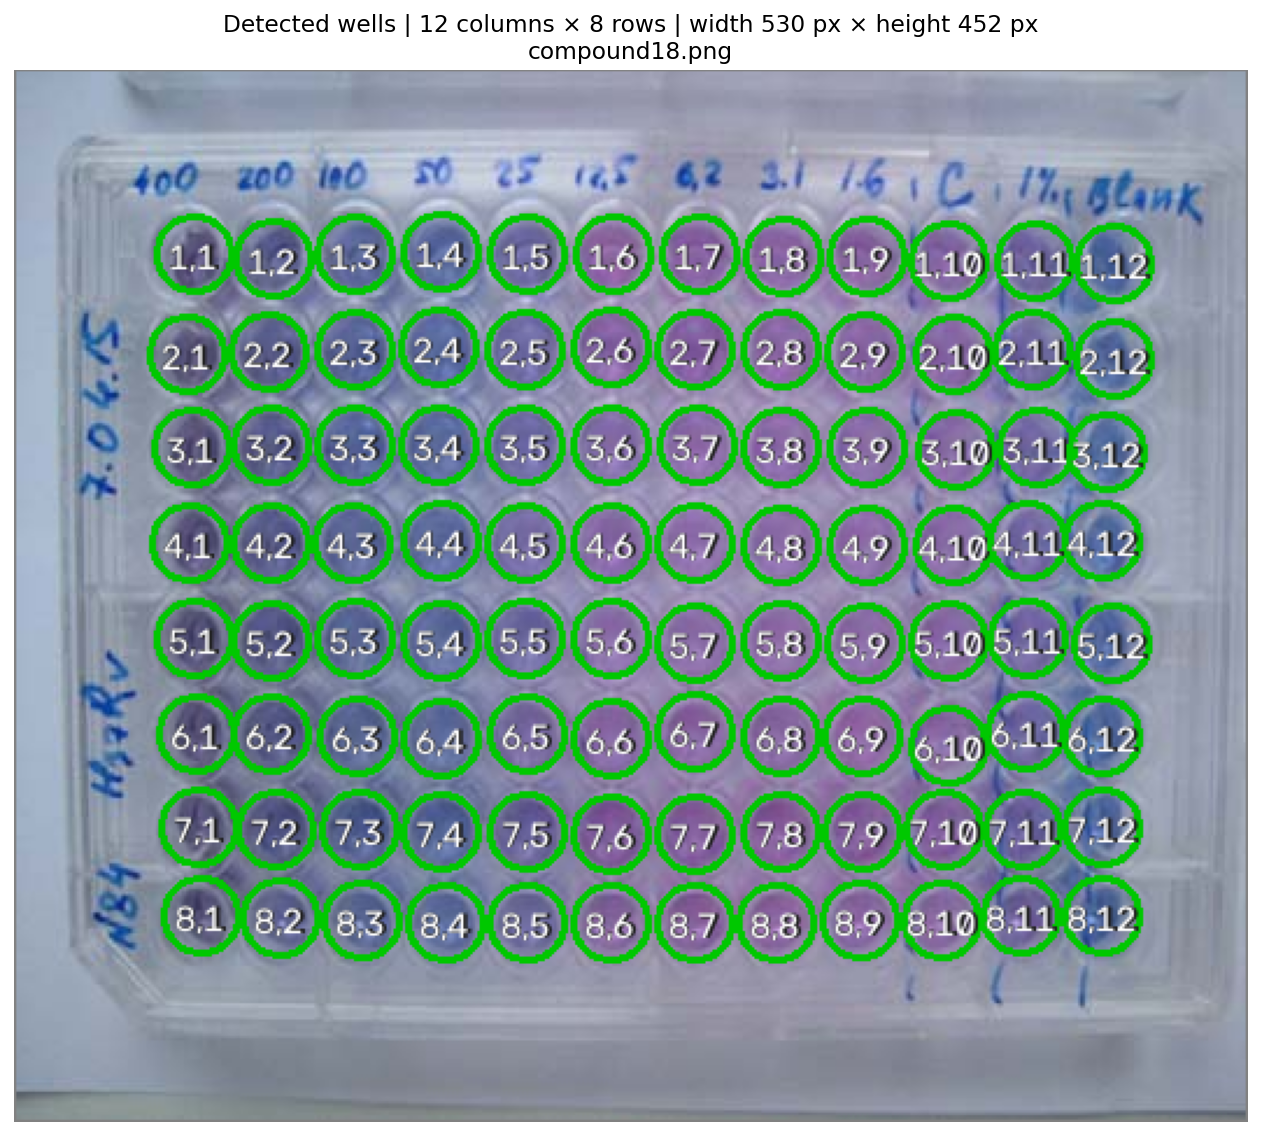

Verify the sampling overlay in the correction form below.


In [ ]:
#@title Detect the 12 × 8 wells { display-mode: "form" }
for _name in ('lattice_df_corrected', 'wells_df', 'preview_signature',
              'lab_summary', 'csv_export'):
    globals().pop(_name, None)
_raw = cv2.imdecode(np.frombuffer(IMAGE_PATH.read_bytes(), np.uint8), cv2.IMREAD_COLOR)
if _raw is None:
    raise ValueError('Cannot decode the uploaded image.')
img_bgr, img_rgb, lattice_df, r_global, diag, cands = detect_and_fit_lattice(_raw)
if not diag['grid_is_12x8']:
    raise RuntimeError('Detection did not produce a complete 12 × 8 structure.')
print('Structure: 12 columns × 8 rows = 96 positions.')
print('Support:', diag['support_counts'])
detected_overlay = draw_overlay(img_bgr, lattice_df, show_labels=True)
fig, ax = plt.subplots(figsize=(13, 8), constrained_layout=True)
ax.imshow(cv2.cvtColor(detected_overlay, cv2.COLOR_BGR2RGB))
height_px, width_px = img_bgr.shape[:2]
ax.set_title(f'Detected wells | 12 columns × 8 rows | width {width_px} px × height {height_px} px\n'
             f'{IMAGE_PATH.name}')
ax.axis('off')
plt.show()
plt.close(fig)
print('Verify the sampling overlay in the correction form below.')


In [ ]:
#@title Optional manual correction of horizontal and vertical shifts { display-mode: "form" }
#@markdown Edit the fields below, then click **Apply shifts and refresh preview**. Shifts are in pixels; positive x moves right and positive y moves down.
if "lattice_df" not in globals():
    raise RuntimeError("Upload and detect an image first.")

# Dispose of a previous form before constructing a new one.
if "correction_panel" in globals():
    correction_panel.close()

def shift_field(label, value=0.0):
    return widgets.FloatText(
        value=value, description=label,
        style={"description_width": "initial"},
        layout=widgets.Layout(width="100%", min_width="0px"),
    )

global_x_input = shift_field("Global x")
global_y_input = shift_field("Global y")
radius_input = widgets.BoundedFloatText(
    value=0.5, min=0.001, max=1.0, step=0.05,
    description="Radius fraction",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="100%", min_width="0px"),
)
column_shift_inputs = {c: shift_field(f"Col {c:02d} x") for c in range(1, 13)}
row_shift_inputs = {r: shift_field(f"Row {r} y") for r in range(1, 9)}

def field_grid(fields, columns):
    return widgets.GridBox(
        children=list(fields),
        layout=widgets.Layout(
            width="100%",
            grid_template_columns=f"repeat({columns}, minmax(0, 1fr))",
            grid_gap="6px 10px",
        ),
    )

global_grid = field_grid([global_x_input, global_y_input, radius_input], 3)
column_shift_grid = field_grid(column_shift_inputs.values(), 4)
row_shift_grid = field_grid(row_shift_inputs.values(), 4)
apply_button = widgets.Button(
    description="Apply shifts and refresh preview", icon="refresh",
    button_style="primary", layout=widgets.Layout(width="290px"),
)
preview_status = widgets.HTML()
preview_output = widgets.Output()

def invalidate_sampling_results():
    for name in (
        "wells_df", "preview_signature", "lab_summary", "csv_export",
        "audited_wells", "screening_tests",
    ):
        globals().pop(name, None)

def sampling_controls_are_current():
    """Prevent final results from using an old preview after an input edit."""
    current = (
        float(global_x_input.value), float(global_y_input.value),
        float(radius_input.value),
        tuple(float(w.value) for w in column_shift_inputs.values()),
        tuple(float(w.value) for w in row_shift_inputs.values()),
    )
    return current == globals().get("applied_controls")

def draw_sampling_preview(_=None):
    global INNER_RADIUS_FRAC, column_shift_map, row_shift_map
    global lattice_df_corrected, wells_df, preview_signature, overlay
    global applied_controls
    invalidate_sampling_results()
    apply_button.disabled = True
    try:
        with preview_output:
            preview_output.clear_output(wait=True)
            gx, gy = float(global_x_input.value), float(global_y_input.value)
            INNER_RADIUS_FRAC = float(radius_input.value)
            column_shift_map = {
                c: gx + float(widget.value) for c, widget in column_shift_inputs.items()
            }
            row_shift_map = {
                r: gy + float(widget.value) for r, widget in row_shift_inputs.items()
            }
            settings = list(column_shift_map.values()) + list(row_shift_map.values())
            if not np.isfinite(settings + [INNER_RADIUS_FRAC]).all():
                raise ValueError("All shifts and the radius fraction must be finite.")
            if not (0 < INNER_RADIUS_FRAC <= 1):
                raise ValueError("Sample radius fraction must be > 0 and <= 1.")
            lattice_df_corrected = lattice_df.copy()
            lattice_df_corrected["x_lattice"] += lattice_df_corrected.column.map(column_shift_map)
            lattice_df_corrected["y_lattice"] += lattice_df_corrected.row.map(row_shift_map)
            wells_df = extract_colors_on_strict_lattice(img_rgb, lattice_df_corrected, r_global)
            preview_signature = hashlib.sha256(wells_df.to_csv(index=False).encode()).hexdigest()
            overlay = draw_overlay(img_bgr, lattice_df_corrected, wells_df, show_labels=False)
            fig, ax = plt.subplots(figsize=(13, 8), constrained_layout=True)
            ax.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
            ax.axis("off")
            plt.show()
            plt.close(fig)
            print("Black: sampling circles. Outer rims: green detected / orange refined / red inferred.")
            print("Inspect the preview before running the results cell.")
            if not wells_df.valid_sample.all():
                print(f"WARNING: {(~wells_df.valid_sample).sum()} invalid samples will be omitted.")
            applied_controls = (
                gx, gy, INNER_RADIUS_FRAC,
                tuple(float(w.value) for w in column_shift_inputs.values()),
                tuple(float(w.value) for w in row_shift_inputs.values()),
            )
            preview_status.value = "<span style='color:#166534'>Preview is up to date.</span>"
    except Exception as exc:
        invalidate_sampling_results()
        preview_status.value = (
            "<span style='color:#b91c1c'>Preview failed. Correct the inputs and apply again.</span>"
        )
        with preview_output:
            print(f"{type(exc).__name__}: {exc}")
    finally:
        apply_button.disabled = False

def mark_preview_stale(change):
    if change["name"] == "value":
        invalidate_sampling_results()
        preview_status.value = (
            "<span style='color:#92400e'>Inputs changed. Apply shifts to refresh the preview.</span>"
        )

for control in (
    global_x_input, global_y_input, radius_input,
    *column_shift_inputs.values(), *row_shift_inputs.values(),
):
    control.observe(mark_preview_stale, names="value")
apply_button.on_click(draw_sampling_preview)
correction_panel = widgets.VBox([
    widgets.HTML("<b>Global shifts and sampling radius</b>"),
    global_grid,
    widgets.HTML("<b>Individual column x-shifts (pixels)</b>"),
    column_shift_grid,
    widgets.HTML("<b>Individual row y-shifts (pixels)</b>"),
    row_shift_grid,
    widgets.HBox([apply_button, preview_status]),
    preview_output,
], layout=widgets.Layout(width="100%", max_width="1100px"))
display(correction_panel)
# Running this cell also renders the default, zero-shift preview.
draw_sampling_preview()


In [ ]:
#@title Column results and CSV download { display-mode: "form" }
#@markdown Assumption: comparable, independent well measurements within each column.
#@markdown Screening is separate from GUM. Review exclusions; disable it for genuinely heterogeneous columns.
automatic_outlier_screening = True #@param {type:"boolean"}
column_alpha = 0.05 #@param {type:"number"}
manual_exclusions = "" #@param {type:"string"}
#@markdown Manual exclusions use numeric row:column pairs, for example `1:3, 8:12`.
#@markdown ### Additional output-scale standard uncertainties
#@markdown Optional aggregate u_B for the COLUMN MEAN, independent of Type A, with effectively infinite degrees of freedom. Defaults mean not supplied. CIELAB units for L*, a*, b*. No division by sqrt(n).
u_B_L = 0.0 #@param {type:"number"}
u_B_a = 0.0 #@param {type:"number"}
u_B_b = 0.0 #@param {type:"number"}

if 'wells_df' not in globals() or 'preview_signature' not in globals():
    raise RuntimeError('Apply shifts in the correction form and inspect its sampling preview first.')
if not sampling_controls_are_current():
    raise RuntimeError('Correction inputs changed. Apply shifts and refresh the preview first.')
if hashlib.sha256(wells_df.to_csv(index=False).encode()).hexdigest() != preview_signature:
    raise RuntimeError('Sampling data changed. Rerun the correction form.')
import json
type_b = {'L*': u_B_L, 'a*': u_B_a, 'b*': u_B_b}
audited_wells, screening_tests = screen_wells(
    wells_df, enabled=automatic_outlier_screening,
    alpha_column=float(column_alpha), manual_text=manual_exclusions,
)
lab_summary = gum_column_summary(audited_wells, LAB_CHANNELS, type_b)
for table in (audited_wells, screening_tests, lab_summary):
    table['image'] = IMAGE_PATH.name
    table['image_sha256'] = IMAGE_SHA256
    table['notebook_version'] = NOTEBOOK_VERSION
    table['sample_radius_fraction'] = INNER_RADIUS_FRAC
    table['column_x_shifts_px'] = json.dumps(column_shift_map, sort_keys=True)
    table['row_y_shifts_px'] = json.dumps(row_shift_map, sort_keys=True)
    table['package_versions'] = json.dumps(PACKAGE_VERSIONS, sort_keys=True)
    table['screening_enabled'] = automatic_outlier_screening
    table['alpha_column'] = float(column_alpha)
    table['manual_exclusions_setting'] = manual_exclusions

display(Markdown('## Final column results\nMean ± combined standard uncertainty, **k=1**. '
                 'Each well is one independent observation; uncertainties are conditional on exclusions.'))
if all(float(value) == 0 for value in type_b.values()):
    print('Type A only: no Type B budget supplied. These are not complete metrological uncertainties.')
else:
    print('Combined Type A + supplied Type B only; unmodelled effects remain outside the budget.')
print(f'Excluded: {int((~audited_wells.included).sum())}/96 '
      f'(automatic suspects: {int(audited_wells.auto_outlier.sum())}; '
      f'manual: {int(audited_wells.manual_excluded.sum())}).')
print('Exclusion records remain in audited_wells and screening_tests (not exported).')
display(Markdown('### CIELAB'))
display(final_table(lab_summary, LAB_CHANNELS).style.hide(axis='index'))
# The ONLY exported table: seven numeric comma-separated columns.
csv_export = pd.DataFrame({
    'Column': lab_summary['column'].astype(int),
    'L*': lab_summary['L*_mean'],
    'a*': lab_summary['a*_mean'],
    'b*': lab_summary['b*_mean'],
    'u_L': lab_summary['L*_u_c'],
    'u_a': lab_summary['a*_u_c'],
    'u_b': lab_summary['b*_u_c'],
})
csv_path = OUTPUT_DIR / f'{IMAGE_STEM}_CIELab_summary.csv'
csv_export.to_csv(csv_path, sep=',', index=False, encoding='utf-8',
                  na_rep='NaN', float_format='%.2f')
print('Saved:', csv_path.name)
if IN_COLAB:
    try:
        files.download(str(csv_path))
    except Exception as exc:
        print(f'Automatic download unavailable: {exc}. '
              'The CSV remains available in the Colab output/ folder.')
else:
    print('Local execution: CSV is at', csv_path.resolve())


## Final column results
Mean ± combined standard uncertainty, **k=1**. Each well is one independent observation; uncertainties are conditional on exclusions.

Type A only: no Type B budget supplied. These are not complete metrological uncertainties.
Excluded: 0/96 (automatic suspects: 0; manual: 0).
Exclusion records remain in audited_wells and screening_tests (not exported).


### CIELAB

column,n,excluded rows,L*: mean ± u_c (k=1),a*: mean ± u_c (k=1),b*: mean ± u_c (k=1)
1,8,,36.91 ± 0.39,10.37 ± 0.38,-20.22 ± 0.25
2,8,,39.80 ± 0.87,9.95 ± 0.25,-24.91 ± 0.32
3,8,,43.59 ± 0.85,7.88 ± 0.38,-27.77 ± 0.66
4,8,,45.79 ± 0.56,7.50 ± 0.25,-28.71 ± 0.47
5,8,,47.02 ± 0.65,15.46 ± 0.57,-29.26 ± 0.43
6,8,,48.60 ± 0.72,25.01 ± 0.56,-27.96 ± 0.61
7,8,,48.67 ± 0.84,25.95 ± 0.58,-27.86 ± 0.41
8,8,,50.11 ± 0.56,25.38 ± 0.58,-26.96 ± 0.30
9,8,,49.92 ± 0.84,25.09 ± 0.59,-26.92 ± 0.31
10,8,,49.97 ± 0.64,23.10 ± 0.62,-26.74 ± 0.58


Saved: compound18_CIELab_summary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Measurement model and uncertainty
One well's mean RGB is one observation. Each well's CIELAB result is the
conversion of that mean sRGB to CIELAB (D65, 2° observer), not the mean of
pixel-wise Lab. The column result is the mean of the retained per-well
measurements. Pixels are not treated as independent replicate measurements.
The wells in a column must be independent, comparable replicates of the same
measurand; colour coordinates themselves need not be independent. RGB is used
only as an internal image representation for conversion to CIELAB.

For each channel, the Type A evaluation uses
$$
\bar x=\frac{1}{n}\sum_i x_i,\qquad
s^2=\frac{\sum_i(x_i-\bar x)^2}{n-1},\qquad
u_A(\bar x)=\frac{s}{\sqrt n},\qquad \nu_A=n-1.
$$
These are the independent-observation formulas in
[JCGM 100:2008, §§4.2.1–4.2.3](https://www.iso.org/sites/JCGM/GUM/JCGM100/C045315e-html/C045315e_FILES/MAIN_C045315e/04_e.html).
Here, $s$ describes between-well dispersion, not uncertainty of the mean.
At least two retained wells are required to estimate $u_A$; otherwise
uncertainties are exported as NaN, never invented as zero.

The reporting form accepts an additional standard uncertainty $u_B$ for
each output channel. The model is $Y=\bar x+\delta_B$, where $\delta_B$
is an aggregate, zero-estimate correction uncertainty in that channel's units.
It is assumed independent of the Type A component, common to the column mean,
and to have effectively infinite degrees of freedom:
$$
u_c=\sqrt{u_A^2+u_B^2}.
$$
The supplied $u_B$ is NOT divided by $\sqrt n$. Do not double-count effects
already represented by between-well scatter. Inputs with finite degrees of
freedom, nonzero corrections, or relevant covariance require a fuller model.
The propagation rule and covariance requirements are given in
[GUM §§5.1–5.2](https://www.iso.org/sites/JCGM/GUM/JCGM100/C045315e-html/C045315e_FILES/MAIN_C045315e/05_e.html).
The tables report **standard uncertainty, k=1**, not an expanded uncertainty
or a 95% coverage interval. Uncertainty is displayed with two significant
figures and the mean at the corresponding decimal place. The downloadable
CSV formats all colour values and uncertainties to two decimal places;
the underlying calculation and the notebook table retain their precision.
`u_L`, `u_a`, and `u_b` contain the combined standard uncertainties of the
retained-well column means (k=1), equal to Type A values when no Type B is supplied.

Default $u_B=0$ means **not supplied**, not that camera calibration, white
balance, illumination gradients, colour-profile errors, sampling geometry,
or other shared effects are absent. With defaults, the reported uncertainty
is Type A only, not a complete GUM uncertainty budget or certified colorimetry.
Correct known biases and quantify relevant effects before claiming full
metrological traceability. Camera RGB values are assumed to be sRGB.

## Outliers and auditability
Automatic screening, enabled by default, applies one two-sided Grubbs test
to each of L*, a*, and b* within each column, using a prespecified column-wise
significance level of 0.05 and Bonferroni allocation (0.05/3 per test).
At most one suspect is tested per channel; tests are not iterated. A well
rejected in any Lab channel is excluded from all three CIELAB summaries,
so all channels use the same set of wells. Clear wells remain eligible.
This is a screening decision separate from GUM, not a GUM-prescribed rule.

[NIST's Grubbs guidance](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h1.htm)
assumes approximately normal observations and a single outlier. With only
eight wells, normality cannot be established reliably; multiple outliers
can mask one another. Review exclusions for physical plausibility and use
manual exclusions or disable screening if the replicate model is inappropriate.
Do not discard real biological/chemical variation just to reduce uncertainty.
Reported post-screening uncertainties are conditional on the retained data
and do not incorporate selection uncertainty. Per-well values, exclusion
reasons, test statistics, and unfiltered summaries remain available in the
Python variables `audited_wells`, `screening_tests`, and `lab_summary`;
they are not separately displayed or exported.
